# Probabilistic FDM — 収束解析 (Matérnカーネル)

PDE: $-u''(x) = \sin(2\pi x)$, $u(0)=u(1)=0$, 真の解 $u(x)=\sin(2\pi x)/(2\pi)^2$

観測ノイズ: $\Sigma = C h^{2\tau} I_{M,N}$

$\tau = 3, 2, 1, 0$ の4パターンで収束レートを比較する。

In [21]:
using Plots
using LinearAlgebra
using SpecialFunctions
using Statistics

## 1. Matérnカーネル・観測行列・周辺尤度

In [22]:
function matern_kernel(x1, x2; ν=1.0, ℓ=1.0)
    r = abs(x1 - x2)
    r == 0 && return 1.0
    z = sqrt(2ν) * r / ℓ
    if ν == 0.5
        return exp(-z)
    elseif ν == 1.5
        return (1 + z) * exp(-z)
    elseif ν == 2.5
        return (1 + z + z^2/3) * exp(-z)
    else
        return (2^(1-ν) / gamma(ν)) * z^ν * besselk(ν, z)
    end
end

# σf=1 固定 (σf^2/C の比だけが効くため)
function kernel_matrix_matern(X1, X2; ν=1.0, ℓ=1.0)
    [matern_kernel(x1, x2; ν=ν, ℓ=ℓ) for x1 in X1, x2 in X2]
end

# 観測行列 H = -Δ_h (負の有限差分ラプラシアン)
# 行順: [bdry_0, int_1, ..., int_{N-1}, bdry_N]
function observation_matrix(n_total, h)
    H = zeros(n_total, n_total)
    H[1, 1]     = 1.0
    H[end, end] = 1.0
    for i in 2:n_total-1
        H[i, i-1] = -1.0 / h^2
        H[i, i]   =  2.0 / h^2
        H[i, i+1] = -1.0 / h^2
    end
    return H
end

u_exact(x) = sin(2π * x) / (2π)^2
f_func(x)  = sin(2π * x)   # PDE右辺: -u'' = f

function make_y_train(x_all)
    vcat(0.0, f_func.(x_all[2:end-1]), 0.0)
end

# log周辺尤度 (σf=1固定, C*h^{2τ} がノイズ)
function log_marginal_matern(
    X, y; H, h, ν, ℓ, C, τ, jitter=1e-10
)
    n = length(X)
    noise_diag      = fill(C * h^(2τ), n)
    noise_diag[1]   = 0.0
    noise_diag[end] = 0.0
    Σ = Diagonal(noise_diag)

    K     = kernel_matrix_matern(X, X; ν=ν, ℓ=ℓ)
    K_obs = H * K * H' + Σ + jitter * I

    local L
    try
        L = cholesky(Hermitian(K_obs)).L
    catch
        return -Inf
    end

    α       = L' \ (L \ y)
    logdetK = 2sum(log.(diag(L)))
    return -0.5*(y'*α) - 0.5*logdetK - 0.5*n*log(2π)
end

log_marginal_matern (generic function with 1 method)

## 2. 収束実験: τ = 3, 2, 1, 0 の4パネル


==================== τ = 3 ====================
  h=0.333: ℓ=1.0, C=0.01, MSE=5.144e-5
  h=0.25: ℓ=1.0, C=0.01, MSE=1.402e-5
  h=0.2: ℓ=1.0, C=0.01, MSE=5.443e-6
  h=0.167: ℓ=1.0, C=0.01, MSE=2.568e-6
  h=0.143: ℓ=1.0, C=0.01, MSE=1.373e-6
  h=0.125: ℓ=1.0, C=0.01, MSE=8.02e-7
  h=0.111: ℓ=1.0, C=0.01, MSE=5.004e-7
  h=0.1: ℓ=1.0, C=0.01, MSE=3.285e-7
  h=0.0833: ℓ=1.0, C=0.01, MSE=1.59e-7
  h=0.0625: ℓ=1.0, C=0.01, MSE=5.071e-8
  h=0.05: ℓ=1.0, C=0.01, MSE=2.094e-8
  h=0.04: ℓ=1.0, C=0.01, MSE=8.669e-9
  h=0.0312: ℓ=1.0, C=0.01, MSE=3.291e-9
  h=0.025: ℓ=1.0, C=0.01, MSE=1.394e-9
  h=0.02: ℓ=1.0, C=0.01, MSE=6.129e-10
  h=0.0156: ℓ=1.0, C=0.01, MSE=2.712e-10
  h=0.0125: ℓ=1.0, C=0.01, MSE=1.509e-10
  h=0.01: ℓ=1.0, C=0.01, MSE=1.014e-10
  h=0.00781: ℓ=1.0, C=0.01, MSE=7.976e-11
  推定 κ ≈ 3.72,  理論 κ = 4.0

==================== τ = 2 ====================
  h=0.333: ℓ=1.0, C=0.01, MSE=5.182e-5
  h=0.25: ℓ=1.0, C=0.01, MSE=1.412e-5
  h=0.2: ℓ=1.0, C=0.01, MSE=5.474e-6
  h=0.167: ℓ=1.0, C

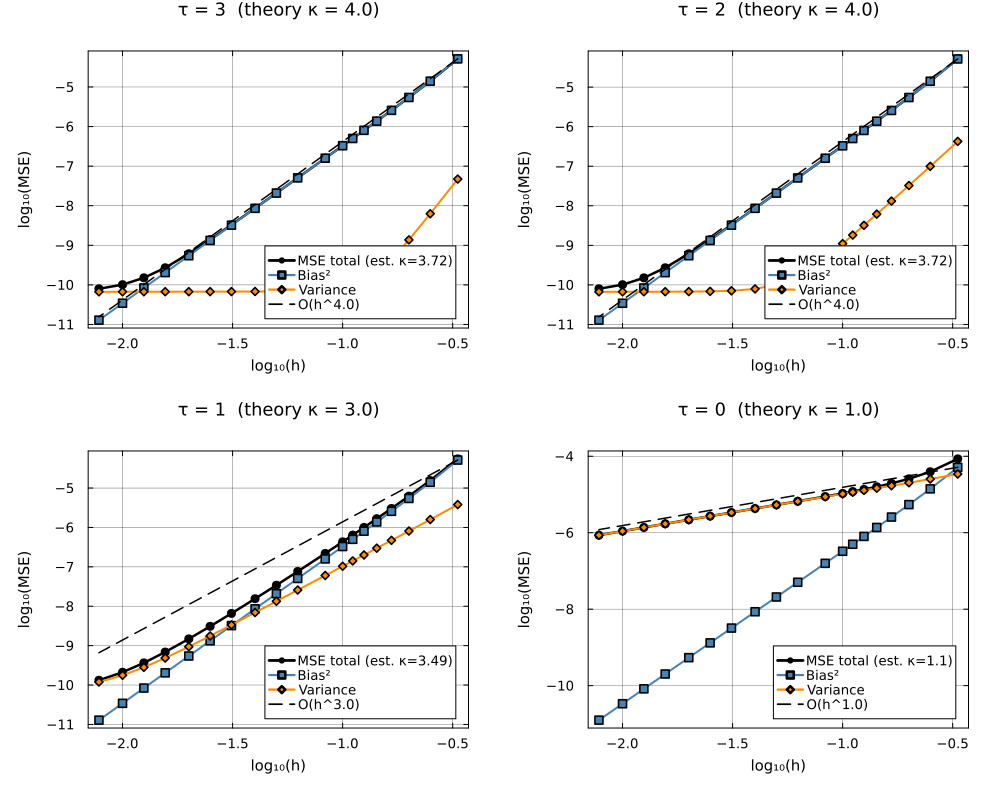

In [23]:
# ============================================================
# 設定
# ============================================================
ν_fixed  = 1.0
τ_list   = [3, 2, 1, 0]

κ_theory = Dict(
    3 => 4.0,
    2 => 4.0,
    1 => 3.0,
    0 => 1.0,
)

K_list = [3, 4, 5, 6, 7, 8, 9, 10, 12, 16, 20, 25, 32, 40, 50, 64, 80, 100, 128]
h_list = 1.0 ./ K_list

ℓ_grid_conv = [0.1, 0.2, 0.3, 0.5, 1.0]
C_grid_conv = 10 .^ range(-2, 2, length=10)

plots_list = []

for τ in τ_list
    println("\n==================== τ = $τ ====================")
    κ = κ_theory[τ]

    mse_bias_list  = Float64[]
    mse_var_list   = Float64[]
    mse_total_list = Float64[]

    for h in h_list
        X       = collect(0.0:h:1.0)
        N       = length(X)
        H_h     = observation_matrix(N, h)
        y_train = make_y_train(X)
        u_true  = u_exact.(X)

        # --- グリッドサーチ ---
        best_score = -Inf
        best_ℓ = ℓ_grid_conv[1]
        best_C = C_grid_conv[1]

        for ℓ in ℓ_grid_conv, C in C_grid_conv
            score = log_marginal_matern(
                X, y_train; H=H_h, h=h,
                ν=ν_fixed, ℓ=ℓ, C=C, τ=τ
            )
            if score > best_score
                best_score = score
                best_ℓ = ℓ
                best_C = C
            end
        end

        # --- 事後分布 ---
        K_prior    = kernel_matrix_matern(X, X; ν=ν_fixed, ℓ=best_ℓ)
        noise_diag = fill(best_C * h^(2τ), N)
        noise_diag[1] = noise_diag[end] = 0.0
        A_mat = H_h * K_prior * H_h' + Diagonal(noise_diag) + 1e-10*I

        α      = A_mat \ y_train
        μ_post = K_prior * H_h' * α
        K_post = K_prior - K_prior * H_h' * (A_mat \ (H_h * K_prior))

        bias_sq  = mean((μ_post .- u_true).^2)
        var_term = tr(K_post) / N
        mse_total = bias_sq + var_term

        push!(mse_bias_list,  bias_sq)
        push!(mse_var_list,   var_term)
        push!(mse_total_list, mse_total)

        println("  h=$(round(h,sigdigits=3)): ℓ=$(round(best_ℓ,sigdigits=3)), C=$(round(best_C,sigdigits=3)), MSE=$(round(mse_total,sigdigits=4))")
    end

    # --- 実測収束レート (線形回帰で推定) ---
    log_h   = log10.(h_list)
    log_mse = log10.(mse_total_list)

    # 最小二乗でスロープを推定
    lh_c  = log_h .- mean(log_h)
    lm_c  = log_mse .- mean(log_mse)
    κ_est = sum(lh_c .* lm_c) / sum(lh_c .^ 2)
    κ_est = round(κ_est, digits=2)
    println("  推定 κ ≈ $κ_est,  理論 κ = $κ")

    # 参照線 (Bias² のみ, MSE total に対応)
    ref_bias = log10.(mse_bias_list)[1] .+ κ .* (log_h .- log_h[1])

    p = plot(
        log_h, log_mse;
        marker=:circle, markersize=5, lw=2.5, color=:black,
        label="MSE total (est. κ=$κ_est)",
        xlabel="log₁₀(h)", ylabel="log₁₀(MSE)",
        title="τ = $τ  (theory κ = $κ)",
        legend=:bottomright,
        titlefontsize=12, legendfontsize=9,
        guidefontsize=10, tickfontsize=9,
        grid=true, gridalpha=0.3, framestyle=:box,
    )
    plot!(p, log_h, log10.(mse_bias_list);
        marker=:square, markersize=4, lw=2,
        color=:steelblue, label="Bias²")
    plot!(p, log_h, log10.(mse_var_list);
        marker=:diamond, markersize=4, lw=2,
        color=:darkorange, label="Variance")
    plot!(p, log_h, ref_bias;
        lw=1.5, ls=:dash, color=:black,
        label="O(h^$(κ))")

    push!(plots_list, p)
end

p_all = plot(plots_list...; layout=(2,2), size=(1000, 800), margin=6Plots.mm)
display(p_all)
savefig(p_all, "matern_convergence.png")
println("Saved: matern_convergence.png")
